# Figure 7 - Ash1 and the SARS-CoV-2 nucleocapsid NTD

Lotthammer, J. M. & Holehouse, A. S. *Disentangling folding from energetic traps in simulations of disordered proteins.* **J. Chem. Inf. Model.** (2025). doi:[10.1021/acs.jcim.4c02005](https://doi.org/10.1021/acs.jcim.4c02005)

**What the figure shows.** PENGUIN applied to two biological disordered regions simulated with extensive Monte Carlo sampling: the yeast Ash1 fragment (residues 420-500 with an N-terminal Gly-Ala, 83 residues; panels B-E) and the N-terminal domain of the SARS-CoV-2 nucleocapsid protein (NTD, 49 residues; panels G-J). The blue band on Ash1 marks residues 39-48, the region with the poorest sampling.

**What to look for.** Both systems sit much closer to the EV limit than the synthetic traps of Figures 5 and 6, and the all-to-all comparison is low - i.e. extensive MC sampling explores conformational space efficiently for these sequences. Ash1 residues 39-48 (around the `YHRFALDSPP` motif) show the largest EV-comparison values together with the largest replicate spread, flagging them as the region to sample longest or scrutinise most carefully.

**Data.** Ash1: 15 FH and 15 EV replicates of 6000 frames. NTD: 15 FH replicates (1000 frames) and 15 EV replicates (500 frames); the paper excluded replicates 16-20 (not included in `data/`), and `truncate=True` trims to 500 frames.

**Caption note.** Again the caption says φ-only while the code and figure use the joint 2D distribution; the 2D version is reproduced here.

## Setup

All notebooks in this directory share `penguin_helpers.py`, a thin layer over SOURSOP's public `soursop.sssampling.SamplingQuality` API that handles data discovery, the manuscript's matplotlib style, and the four-panel PENGUIN figure. The trajectories (~6 GB) live in `data/`, one folder per system with `full/` and `ev/` replicates (see `data/README.md`); they are too large for the SOURSOP repository, so set `PENGUIN_DATA_DIR` if you keep them elsewhere.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from penguin_helpers import (
    set_manuscript_style, get_data_dir, figure_path, load_system,
    penguin_figure, print_sequence,
)

set_manuscript_style()
%matplotlib inline
%config InlineBackend.figure_format = 'retina'

DATA_DIR = get_data_dir()
print("Reading simulation data from", DATA_DIR)

Reading simulation data from /Users/alex/Dropbox/WASHU/Holehouse/tools/soursop/soursop/demo_examples/penguin/data


## Ash1 - Monte Carlo replicates

In [2]:
ash1 = load_system("ash1/full", "ash1/ev", num_replicates=15,
                   method="2D angle distributions", truncate=True)
ash1_sequence = print_sequence(ash1)

15 FH replicates, 15 EV replicates


Successfully truncated.
                The shortest trajectory is: 6000 frames.                All trajectories truncated to 6000


GASASSSPSPSTPTKSGKMRSRSSSPVRPKAYTPSPRSPNYHRFALDSPPQSPRRSSNSSITKKGSRRSSGSSPTRHTTRVCV
.........1.........2.........3.........4.........5.........6.........7.........8...


## How to read a PENGUIN figure

Every PENGUIN summary has the same four panels (the sequence cartoon shown as panel **A** in the paper was drawn in a vector graphics editor, so here we print the sequence with a ruler instead):

* **B - Comparison to the excluded-volume limit.** For every residue and every full-Hamiltonian (FH) replicate, the joint (φ, ψ) distribution is histogrammed and compared to the same residue in the excluded-volume (EV) reference ensemble using the Hellinger distance (0 = identical, 1 = no overlap). Red points are individual replicates; the black line is the replicate mean. Low values mean the residue explores its backbone conformational space about as freely as a chain with no attractive interactions; high values mean the FH ensemble is restricted relative to that limit - which can be genuine structure *or* an energetic trap.
* **C - All-to-all trajectory comparison.** The same Hellinger distance, but between every pair of FH replicates. If independent replicates agree with one another (low values) the restriction seen in **B** is reproducible and therefore reflects the Hamiltonian; if they disagree (high values) each replicate is stuck somewhere different - the signature of poor sampling.
* **D - Spread of B.** The maximum minus minimum Hellinger distance across replicates, per residue; a compact summary of how consistently a residue is scored against the EV limit.
* **E - Fractional helicity.** Per-residue DSSP helicity of the FH replicates, so that any restriction in **B** can be checked against a concrete structural explanation.

The logic of the method is that **B** on its own cannot distinguish folding from trapping, but **B** together with **C** can: reproducible structure gives high **B** / low **C**, whereas energetic traps give high **B** / high **C**.

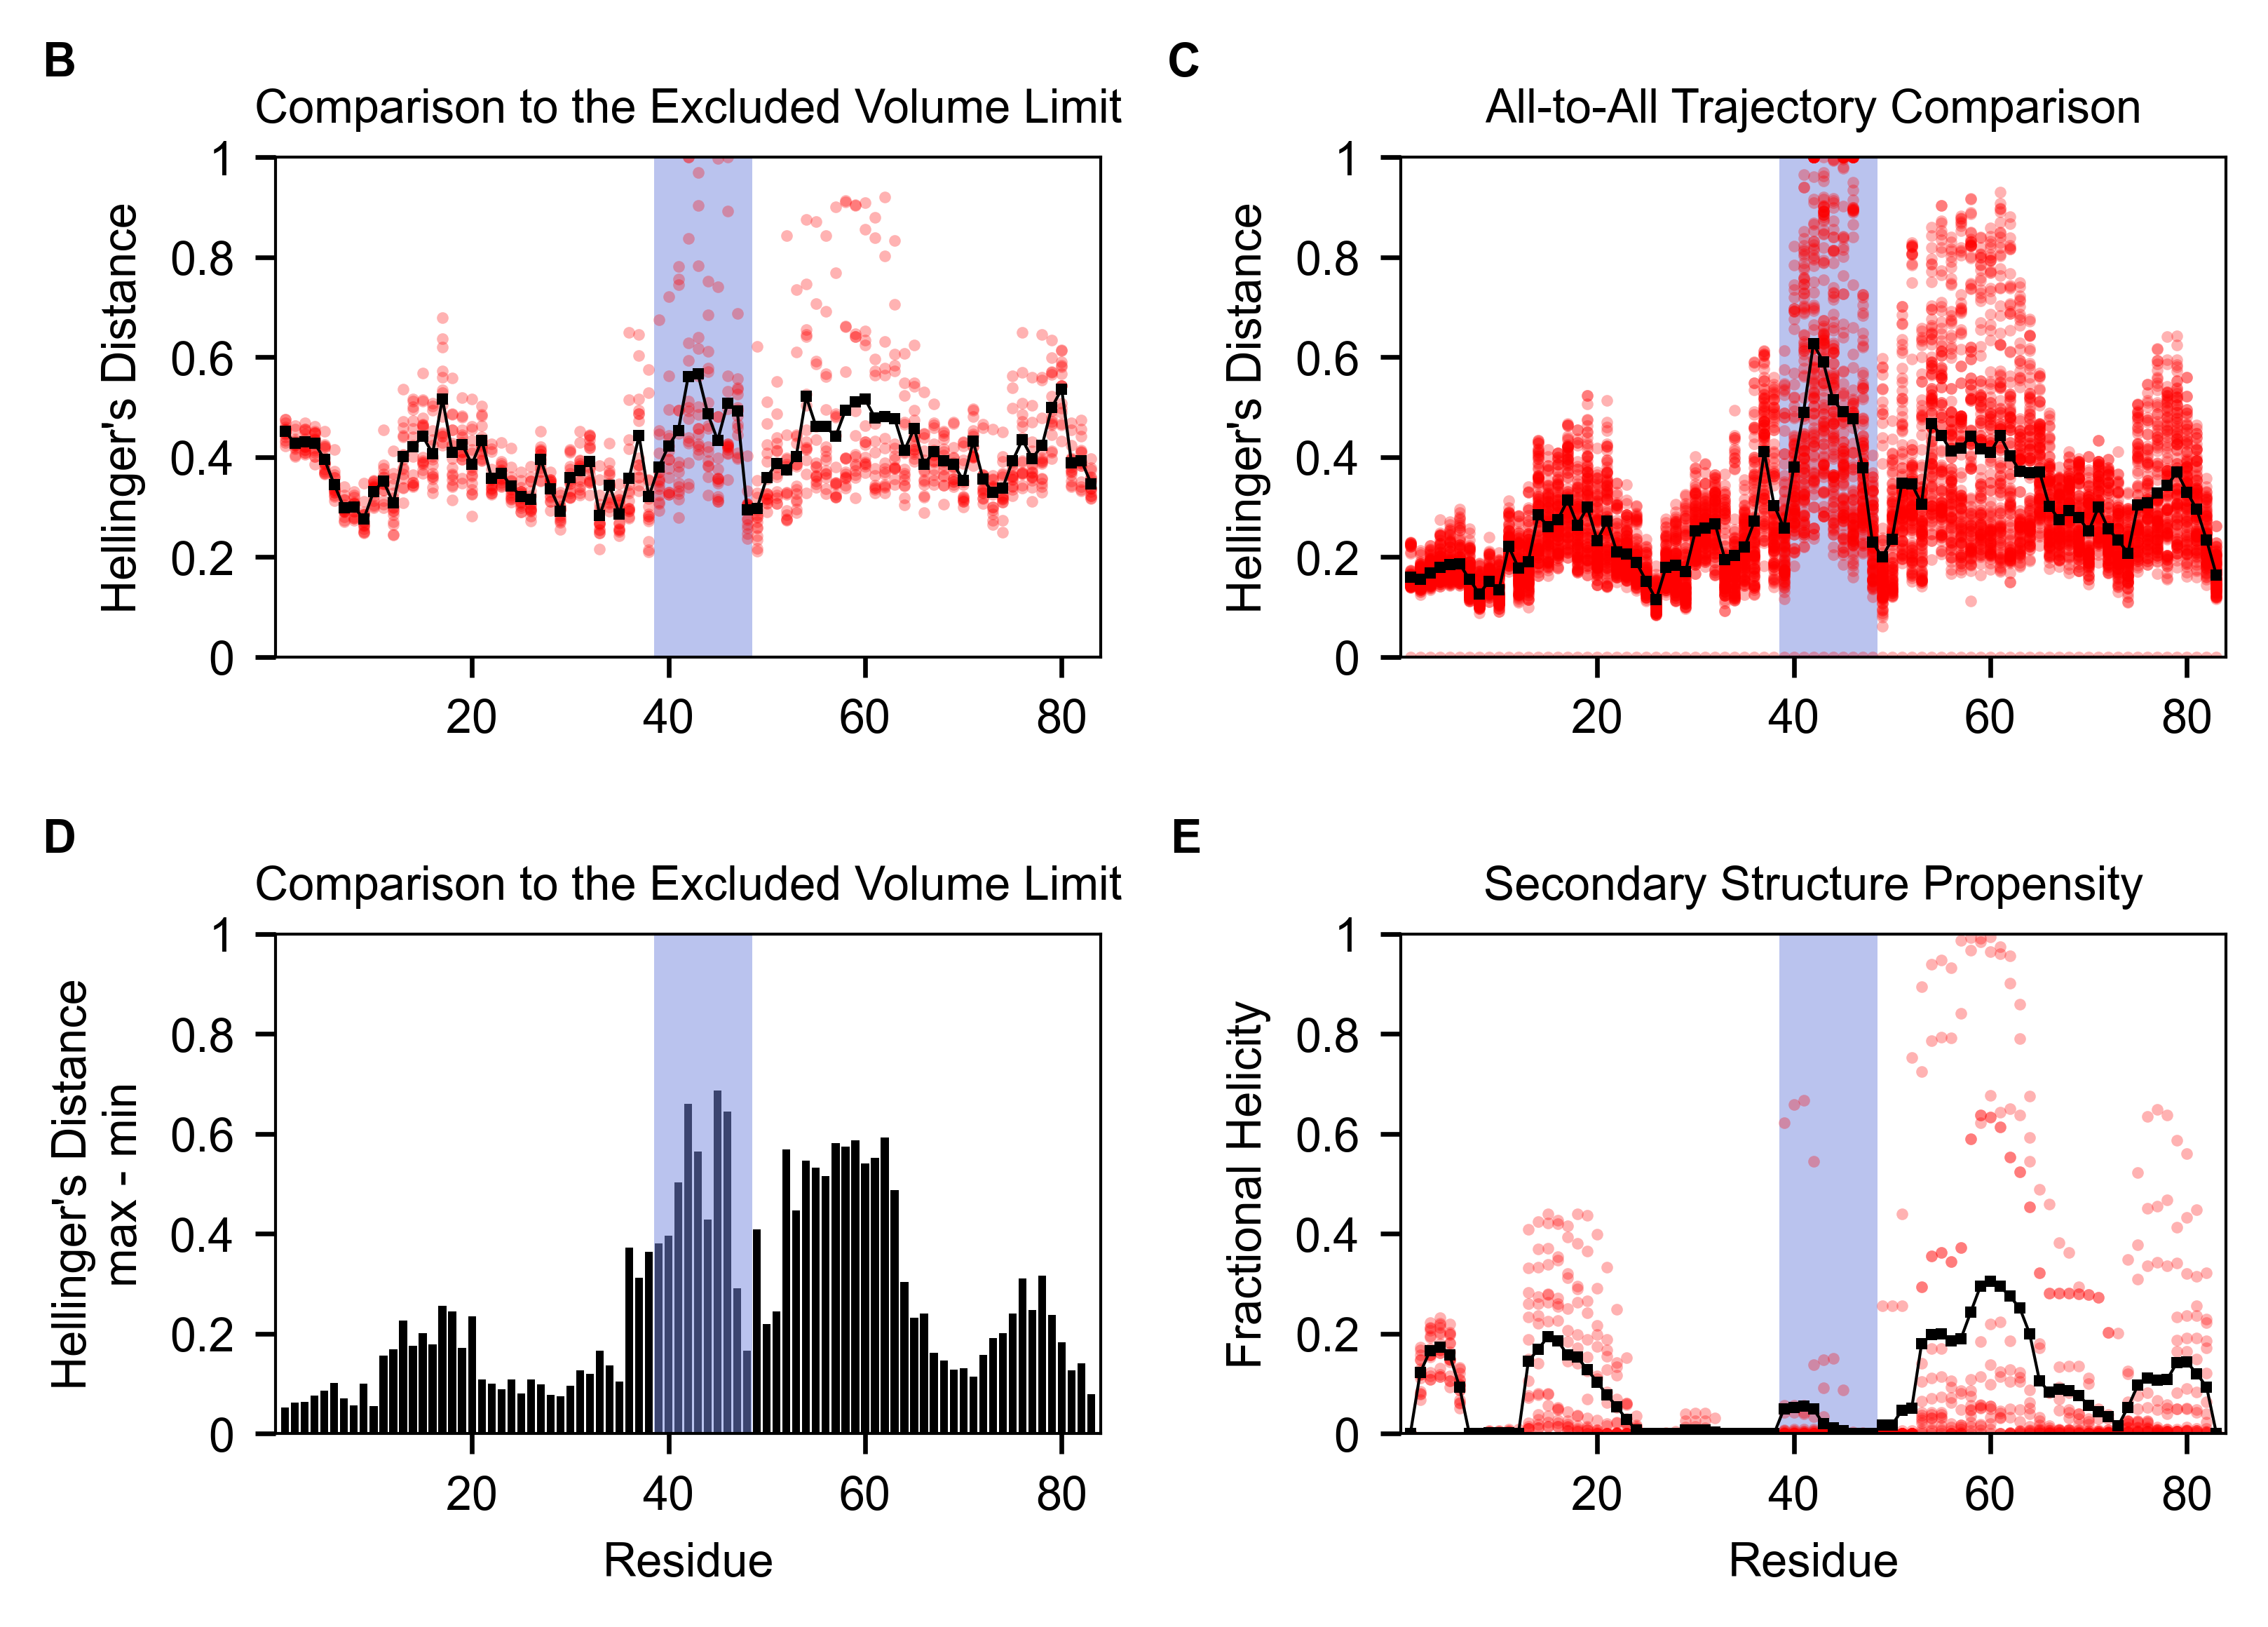

In [3]:
fig, axd = penguin_figure(ash1, dihedral="2D", increment=20, figsize=(5.5, 4), fontsize=8,
                          highlight=(38.5, 48.5), color="#7689de",
                          label_position=(-0.1, 1.15), panel_labels=("B", "C", "D", "E"),
                          save_path=figure_path("fig7", "ash1_2D_hellingers.pdf"))

### Which Ash1 residues sample worst?

Ranking residues by their replicate-mean EV-comparison value picks out the region highlighted in the paper.

In [4]:
H = np.asarray(ash1.hellingers_distances()).mean(axis=0)
worst = np.argsort(H)[::-1][:10] + 1
print("ten highest EV-comparison residues:", sorted(worst))
print("residues 39-48:", ash1_sequence[38:48])

ten highest EV-comparison residues: [np.int64(17), np.int64(42), np.int64(43), np.int64(46), np.int64(54), np.int64(58), np.int64(59), np.int64(60), np.int64(79), np.int64(80)]
residues 39-48: PNYHRFALDS


## SARS-CoV-2 nucleocapsid NTD

In [5]:
ntd = load_system("ntd/full", "ntd/ev", num_replicates=15,
                  method="2D angle distributions", truncate=True)
ntd_sequence = print_sequence(ntd)

15 FH replicates, 15 EV replicates


Successfully truncated.
                The shortest trajectory is: 500 frames.                All trajectories truncated to 500


MSDNGPQNQRNAPRITFGGPSDSTGSNQNGERSGARSKQRRPQGLPNNT
.........1.........2.........3.........4.........


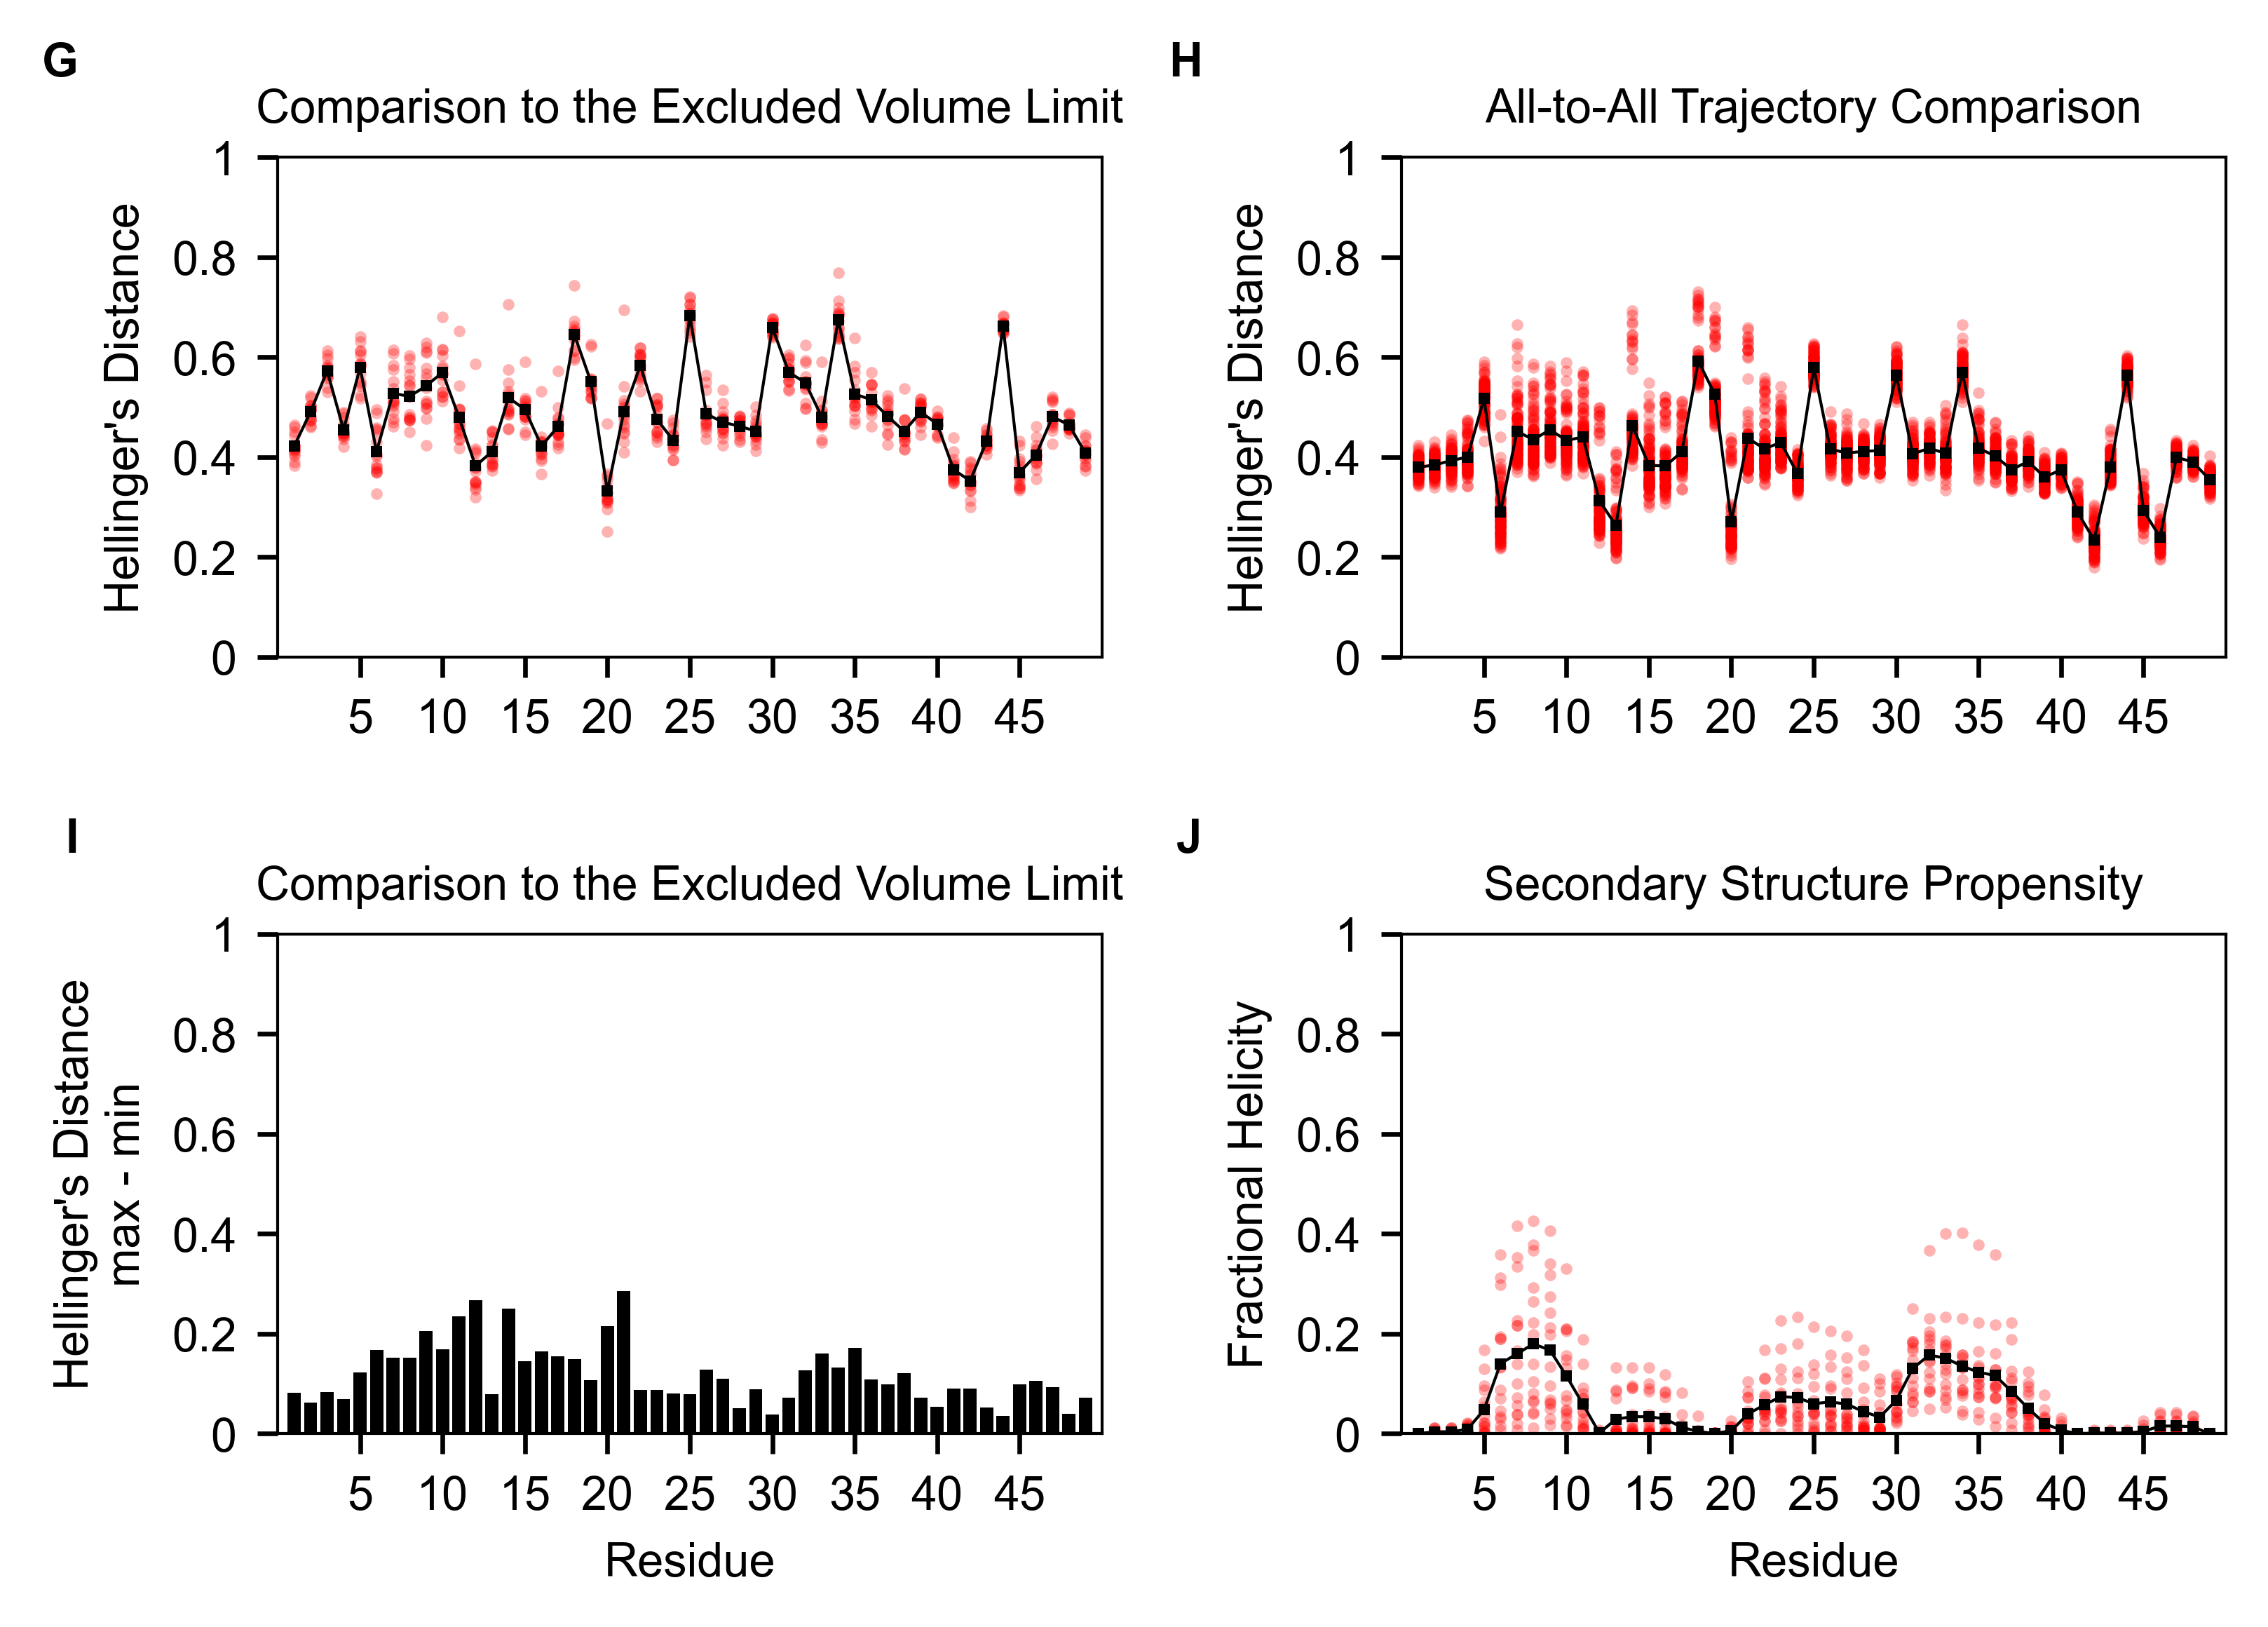

In [6]:
fig, axd = penguin_figure(ntd, dihedral="2D", increment=5, figsize=(5.5, 4), fontsize=8,
                          label_position=(-0.1, 1.15), panel_labels=("G", "H", "I", "J"),
                          save_path=figure_path("fig7", "ntd_2D_hellingers.pdf"))